In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os
import warnings

os.environ["TQDM_DISABLE"] = "1"
# plot_swanson_vector warns about regions with no value; the plot is correct
warnings.filterwarnings('ignore', message='All-NaN slice encountered')

# From your results to what's known

You have one number per brain area: a decoding accuracy, a response latency, a firing rate. Which
genes and cell types vary the same way across those areas? This tutorial answers that with one
pattern, which works for every dataset registered to the atlas: label the dataset's voxels at the
same region level as your result, average within each region, then compare.

If you are new to `iblatlas`, start with [From coordinates to a brain figure](from-coordinates-to-a-brain-figure.ipynb).

## 1. Your per-region result

As a stand-in for your result, this tutorial uses a published per-area number: the cortical
hierarchy score of Harris et al. (2019). The scores come with the connectivity data. Keep the
cortical areas and one score per area. The areas are named at the Beryl level, so everything
below is matched to Beryl; see
[The four mappings](../explanation/brain-region-mappings.qmd#the-four-mappings).

In [2]:
import pandas as pd
from iblatlas.connectivity import mesoscale

hierarchy = mesoscale.load_hierarchy()
hierarchy = hierarchy[(hierarchy['correction'] == 'cre_conf') & (hierarchy['region_type'] == 'C')]
# three insular areas are spelled differently in this file than in the atlas
hierarchy = hierarchy.replace({'area': {'Aid': 'AId', 'Aip': 'AIp', 'Aiv': 'AIv'}})

# Your own result goes here: a pandas Series of values indexed by Beryl acronym
result = hierarchy.set_index('area')['cctcct_iter']
result.head()

area
ACAd    0.358589
ACAv    0.249408
AId     0.127554
AIp    -0.094928
AIv     0.332424
Name: cctcct_iter, dtype: float64

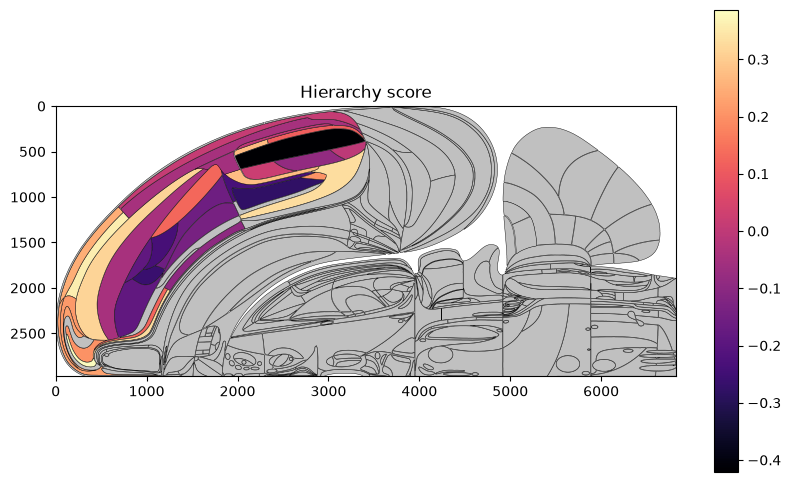

In [3]:
import matplotlib.pyplot as plt
from iblatlas.atlas import AllenAtlas
from iblatlas.plots import plot_swanson_vector

ba = AllenAtlas()
fig, ax = plt.subplots(figsize=(10, 6))
plot_swanson_vector(result.index.to_numpy(), result.to_numpy(), br=ba.regions, cmap='magma',
                    empty_color='silver', show_cbar=True, ax=ax)
ax.set_title('Hierarchy score');

## 2. Load gene expression

The Allen gene expression atlas holds one volume per in situ experiment. The first run downloads
about 1.4 GB; see [Data downloads and caching](../explanation/data-downloads-and-caching.qmd). The volumes sit
on their own 200 µm grid, with their own atlas object, `atlas_agea`. See
[How the genomics volumes differ](../explanation/external-data-in-the-common-space.qmd#how-the-genomics-volumes-differ)
and [Raw and processed gene expression](../explanation/external-data-in-the-common-space.qmd#raw-and-processed-gene-expression).

In [4]:
from iblatlas.genomics import agea

df_genes, gene_volumes, atlas_agea = agea.load(label='processed')
print(f'{len(df_genes)} experiments covering {df_genes["gene"].nunique()} genes, volume shape {gene_volumes.shape}')

4345 experiments covering 4082 genes, volume shape (4345, 58, 41, 67)


## 3. Label every voxel at the same level as your result

`atlas_agea.label` holds a region index for each voxel. Map the indices to Beryl and then to Allen
ids, so that each voxel carries the id of the Beryl region it is in. See
[Three identifiers](../explanation/brain-region-hierarchy.qmd#three-identifiers-and-they-are-not-interchangeable)
for why the label volume holds indices rather than ids.

In [5]:
import numpy as np

regions = atlas_agea.regions
voxel_ids = regions.id[regions.mappings['Beryl'][atlas_agea.label]].ravel()
area_ids = regions.acronym2id(result.index.to_numpy())

## 4. Average each gene within each area

For every experiment, average its volume over the voxels of each area. The function is used again
for cell types in step 7. Values at the very front of the brain are inferred in the processed
volume, not measured.

In [6]:
def mean_per_area(volumes, voxel_ids, area_ids):
    """Average each volume over the voxels of each area: (n_volumes, n_areas)."""
    flat = volumes.reshape(volumes.shape[0], -1)
    return np.stack([np.nanmean(flat[:, voxel_ids == i], axis=1, dtype=np.float32) for i in area_ids], axis=1)


gene_means = pd.DataFrame(mean_per_area(gene_volumes, voxel_ids, area_ids), columns=result.index)
gene_means.insert(0, 'gene', df_genes['gene'])
gene_means.iloc[:5, :6]

area,gene,ACAd,ACAv,AId,AIp,AIv
0,Ndufa10,15.881577,14.924171,15.426061,14.794840,14.697954
1,Grik2,7.764309,9.954553,4.999532,7.551548,5.729222
2,Dmp1,0.095195,0.180450,0.026918,0.048612,0.071199
3,Hnrnpdl,0.336069,0.305679,0.945937,1.950184,1.003226
4,Wdr31,0.534553,0.345125,0.900292,1.127360,0.897232


## 5. Which genes follow your result?

Rank each experiment by its Spearman correlation with the hierarchy score across the 37 areas.
Some genes have more than one experiment, so a gene can appear twice. With about 4,000 genes and 37
areas, strong correlations turn up by chance too: treat the ranking as a starting point for
exploration, not a statistical test.

In [7]:
from scipy.stats import spearmanr


def rank_against(means, result):
    """Spearman rho of each row of means against result, across areas."""
    return np.array([spearmanr(row, result).statistic for row in means])


genes = pd.DataFrame({'gene': df_genes['gene'],
                      'rho': rank_against(gene_means[result.index].to_numpy(), result.to_numpy())})
genes = genes.sort_values('rho', key=abs, ascending=False)
print('Strongest positive'); print(genes.nlargest(5, 'rho').to_string(index=False))
print('Strongest negative'); print(genes.nsmallest(5, 'rho').to_string(index=False))

Strongest positive
  gene      rho
 Ptcd2 0.745140
 Sparc 0.743006
Zfp462 0.732812
 Gpr83 0.719535
  Aif1 0.715031
Strongest negative
         gene       rho
      Tspan11 -0.689189
         Cux1 -0.686107
         Rorb -0.683973
2010111I01Rik -0.669749
        Sgpp2 -0.652205


## 6. Look at the top gene

Take the gene with the strongest correlation and compare its expression per area with the hierarchy
on the Swanson map, then look at one coronal slice of its volume. Further down the ranking, the
layer markers *Cux1* and *Rorb* are among the strongest negative correlations: they are higher in
the primary sensory areas, at the bottom of the hierarchy.

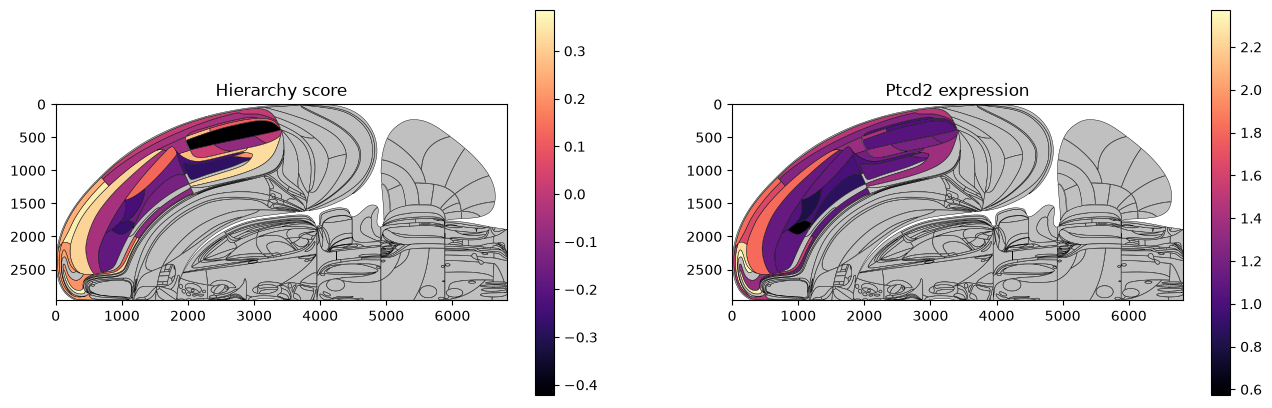

In [8]:
top = genes.index[0]
top_gene = genes.loc[top, 'gene']

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for ax, values, title in zip(axs, (result, gene_means.loc[top, result.index]),
                             ('Hierarchy score', f'{top_gene} expression')):
    plot_swanson_vector(result.index.to_numpy(), values.to_numpy(dtype=float), br=ba.regions,
                        cmap='magma', empty_color='silver', show_cbar=True, ax=ax)
    ax.set_title(title)

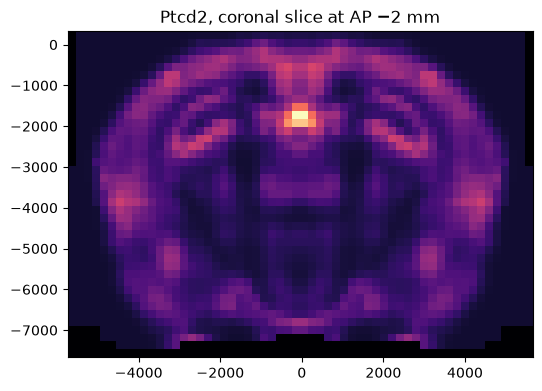

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
atlas_agea.plot_cslice(-0.002, volume=gene_volumes[top], cmap='magma', ax=ax)
ax.set_title(f'{top_gene}, coronal slice at AP −2 mm');

## 7. Same recipe with cell types

The MERFISH cell-type densities sit on the same 200 µm grid, so the voxel labels from step 3 apply
as they are. `merfish.load_volume` returns the denoised volume, neurons only, by default, while
`agea.load` returns the raw one; this tutorial uses the processed volume for both. Some cell types
are absent from all these areas, so their densities are constant and they are left out before
ranking.

In [10]:
from iblatlas.genomics import merfish

type_volumes, type_ids, _ = merfish.load_volume(level='subclass')
df_subclasses = merfish.load()[2]

type_means = mean_per_area(type_volumes, voxel_ids, area_ids)
varies = type_means.std(axis=1) > 0
cell_types = pd.DataFrame({'subclass': df_subclasses.loc[type_ids[varies], 'subclass'].to_numpy(),
                           'rho': rank_against(type_means[varies], result.to_numpy())})
print('Strongest positive'); print(cell_types.nlargest(5, 'rho').to_string(index=False))
print('Strongest negative'); print(cell_types.nsmallest(5, 'rho').to_string(index=False))

Strongest positive
                 subclass      rho
051 Pvalb chandelier Gaba 0.650782
       022 L5 ET CTX Glut 0.648649
       032 L5 NP CTX Glut 0.568516
            047 Sncg Gaba 0.567093
          036 HPF CR Glut 0.529872
Strongest negative
               subclass       rho
   006 L4/5 IT CTX Glut -0.563537
311 CBX MLI Megf11 Gaba -0.453750
       029 L6b CTX Glut -0.440256
      197 SNr Six3 Gaba -0.388834
     128 VMH Fezf1 Glut -0.354026


The cell types tell the same story as the genes: layer 4 neurons (`L4/5 IT CTX Glut`) are
denser at the bottom of the hierarchy, and layer 5 extratelencephalic neurons towards the top.

## 8. Cite the data

If you use these datasets, cite the Allen gene expression atlas, the MERFISH cell types and Harris
et al. (2019) for the hierarchy; see [Citations](../citations.qmd).

## 9. Where next

- Lipids follow the same recipe: [Which lipids are in my region?](../how-to/load-lipids.ipynb)
- Connectivity between regions is a region-by-region matrix rather than one value per region:
  [Load mesoscale connectivity and the cortico-thalamic hierarchy](../how-to/load-mesoscale-connectivity.ipynb)
- More on each dataset: [Which genes are expressed in my region?](../how-to/load-gene-expression-agea.ipynb),
  [Which cell types are in my region?](../how-to/load-merfish.ipynb) and
  [External data in the common space](../explanation/external-data-in-the-common-space.qmd)